# Example 3: a recurrent neural network

The first two examples wrapped hand-written arithmetic. This one wraps a
network that is actually trained: a small recurrent neural network (RNN) that
predicts the temperature at the centre of a metal plate heated from one side.

Along the way it shows three things you will need for real models:

- how to **bake the normalisation of the data into the exported model**, so
  that the FMU works directly with physical units;
- what happens when an input is a **large tensor**: here a window of 200 time
  steps with 2 features becomes 400 scalar inputs of the FMU;
- how to check the FMU against the PyTorch model.

Training takes a while, so the notebook loads the trained weights stored next
to it in `example3.pt`. Set `FORCE_RETRAIN = True` further down to train
again.

In [1]:
import json
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnx
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split

RAW_DATA_DIR = Path("heat-propagation-data")
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

## The physical system

A square plate starts at a uniform temperature. One of its edges is held at a
temperature `u(t)` that changes in time, and the other three edges are held
at zero. Heat diffuses through the plate, and we record the temperature `y(t)`
at its centre.

The plate is simulated with an explicit finite-difference scheme for the heat
equation. This simulator is our source of data: it plays the role of the
expensive, high-fidelity model that the network is meant to replace.

In [2]:
Lx, Ly = 10.0, 10.0   # length and width of the plate
Nx, Ny = 50, 50       # grid points in each direction
dx, dy = Lx / Nx, Ly / Ny
alpha = 0.9           # thermal diffusivity
dt = 0.01             # time step


def run_simulation(alpha, u, T_ini):
    """Temperature at the centre of the plate for the boundary profile `u`.

    Parameters
    ----------
    alpha : float
        Thermal diffusivity of the plate.
    u : np.ndarray
        Temperature imposed on the heated edge at each time step.
    T_ini : float
        Initial temperature of the plate.
    """
    previous = np.full((Nx, Ny), T_ini)
    centre = np.empty(len(u))
    centre[0] = previous[Nx // 2, Ny // 2]
    for n in range(1, len(u)):
        current = np.zeros((Nx, Ny))
        # The heated edge follows the imposed temperature profile
        current[:, 0] = u[n]
        # Explicit finite-difference update of the interior points
        current[1:-1, 1:-1] = previous[1:-1, 1:-1] + alpha * dt * (
            (previous[2:, 1:-1] - 2 * previous[1:-1, 1:-1] + previous[:-2, 1:-1]) / dx**2
            + (previous[1:-1, 2:] - 2 * previous[1:-1, 1:-1] + previous[1:-1, :-2]) / dy**2
        )
        centre[n] = current[Nx // 2, Ny // 2]
        previous = current
    return centre

Here is one simulation: the edge temperature follows a sine wave, and the
centre of the plate responds with a delay and a much smaller amplitude.

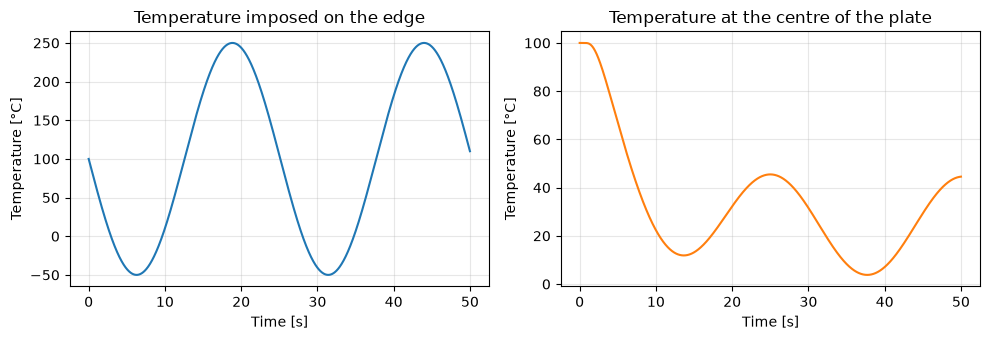

In [3]:
T = 50.0                 # duration of a simulation
Nt = int(T / dt)         # number of time steps
t = np.linspace(0, T, Nt)

T_ini = 100.0
u_demo = -150 * np.sin(t / 4) + T_ini
y_demo = run_simulation(alpha, u_demo, T_ini)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(t, u_demo)
axes[0].set_title("Temperature imposed on the edge")
axes[1].plot(t, y_demo, color="C1")
axes[1].set_title("Temperature at the centre of the plate")
for ax in axes:
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Temperature [°C]")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Training data

The data set is made of 50 simulations. In each one the edge temperature is a
sine wave with a different amplitude and phase. Every simulation is saved to
its own CSV file.

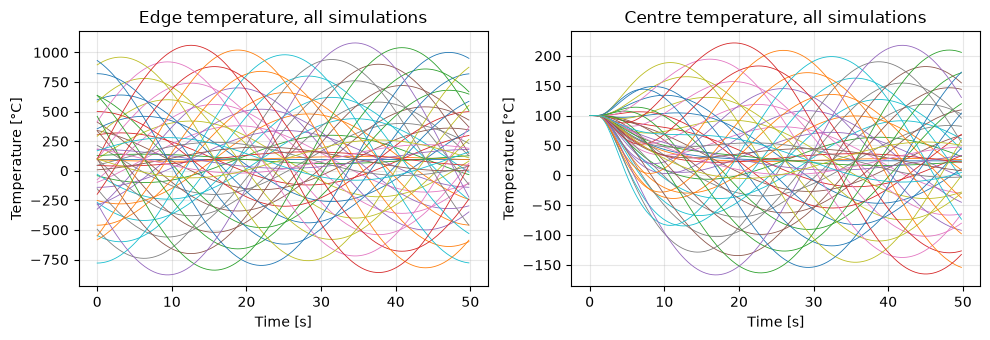

In [4]:
M = 50          # number of simulations
T_plate = 100.0

for i in range(M):
    u = (-1)**i * 20 * i * np.sin(t / 8 + i * np.pi / 8) + T_ini
    y = run_simulation(alpha, u, T_plate)
    pd.DataFrame({"time": t, "u": u, "y": y}).to_csv(
        RAW_DATA_DIR / f"case_{i}.csv", index=False)

data = [pd.read_csv(file) for file in sorted(RAW_DATA_DIR.glob("case_*.csv"))]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for series in data:
    axes[0].plot(series["time"][::20], series["u"][::20], lw=0.6)
    axes[1].plot(series["time"][::20], series["y"][::20], lw=0.6)
axes[0].set_title("Edge temperature, all simulations")
axes[1].set_title("Centre temperature, all simulations")
for ax in axes:
    ax.set_xlabel("Time [s]")
    ax.set_ylabel("Temperature [°C]")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Forty simulations are used for training and ten are kept aside for testing.

The network trains better on values between 0 and 1, so we compute the
minimum and maximum of the training data. We will need these four numbers
again when we export the model.

In [5]:
random.seed(42)
torch.manual_seed(1234)

data_shuffled = random.sample(data, len(data))
train_size = int(0.8 * len(data))
train_data = data_shuffled[:train_size]
test_data = data_shuffled[train_size:]

train_values = pd.concat(train_data)
x_min = train_values[["u", "y"]].min().to_numpy(dtype=np.float32)
x_max = train_values[["u", "y"]].max().to_numpy(dtype=np.float32)
y_min = np.float32(train_values["y"].min())
y_max = np.float32(train_values["y"].max())

print(f"inputs  (u, y): min {x_min}, max {x_max}")
print(f"output  y     : min {y_min}, max {y_max}")

inputs  (u, y): min [-879.99994 -166.76768], max [1080.      221.5708]
output  y     : min -166.76768493652344, max 221.57080078125


## The network

The network looks at a window of the last 200 time steps. For each step it
receives two features: the edge temperature `u` and the centre temperature
`y`. From this window it predicts the centre temperature at the next step.

**Why a window?** An ONNX model is stateless: it cannot keep a hidden state
from one call to the next. The simplest way around this is to give the
network all the history it needs at every call, which is what we do here.
The other way is to hand the hidden state back to the model with *feedback
states*, shown in [Example 4](../example4/example4.ipynb).

In [6]:
seq_length = 200   # time steps in a window
input_size = 2     # features per time step: u and y
hidden_size = 32
output_size = 1


class HeatRNN(nn.Module):

    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=1, batch_first=True)
        self.fc1 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x, _ = self.rnn(x)
        x = self.fc1(x)
        # Keep only the prediction after the last step of the window
        return x[:, -1, :].squeeze(-1)


model = HeatRNN(input_size, hidden_size, output_size)

window = torch.randn(1, seq_length, input_size)
print("input shape: ", tuple(window.shape))
print("output shape:", tuple(model(window).shape))

input shape:  (1, 200, 2)
output shape: (1,)


## Train, or load the trained weights

`make_windows` cuts a simulation into overlapping windows and scales them to
the range 0 to 1. `train` is a standard PyTorch training loop.

With the settings below, training runs for 1000 epochs. To keep the notebook
quick, the weights of a finished training run are stored in `example3.pt` and
loaded here. Set `FORCE_RETRAIN = True` to train from scratch.

In [7]:
def make_windows(series):
    """Normalised input windows and targets for one simulation."""
    x = (series[["u", "y"]].to_numpy(dtype=np.float32) - x_min) / (x_max - x_min)
    y = (series["y"].to_numpy(dtype=np.float32) - y_min) / (y_max - y_min)
    windows = np.lib.stride_tricks.sliding_window_view(x, seq_length, axis=0)
    # sliding_window_view puts the window axis last: (n, features, seq_length)
    windows = windows.transpose(0, 2, 1)[:-1]
    targets = y[seq_length:]
    return windows, targets


def train(model, epochs=1000, batch_size=4096, lr=1e-5):
    windows, targets = zip(*[make_windows(series) for series in train_data])
    dataset = TensorDataset(
        torch.from_numpy(np.concatenate(windows)),
        torch.from_numpy(np.concatenate(targets)),
    )
    train_set, val_set = random_split(dataset, [0.8, 0.2])
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_set, batch_size=batch_size)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"training on {device}")
    model.to(device)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                val_loss += loss_fn(model(x), y).item()

        history.append({"train_loss": train_loss / len(train_loader),
                        "val_loss": val_loss / len(val_loader)})
        print(f"\repoch {epoch + 1}/{epochs}  "
              f"train loss {history[-1]['train_loss']:.2e}  "
              f"validation loss {history[-1]['val_loss']:.2e}", end="")

    model.cpu()
    history = pd.DataFrame(history)
    history.index.name = "epoch"
    return history

loaded trained weights from example3.pt


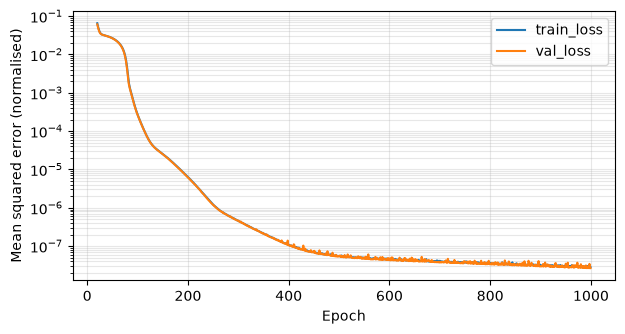

In [8]:
WEIGHTS_PATH = Path("example3.pt")
FORCE_RETRAIN = False

if WEIGHTS_PATH.exists() and not FORCE_RETRAIN:
    model.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
    print(f"loaded trained weights from {WEIGHTS_PATH}")
else:
    history = train(model)
    torch.save(model.state_dict(), WEIGHTS_PATH)
    history.to_csv("loss.csv")
    print(f"\ntrained and saved weights to {WEIGHTS_PATH}")

model.eval()

# Loss history of the training run that produced the weights
history = pd.read_csv("loss.csv", index_col="epoch")
ax = history.iloc[20:].plot(logy=True, figsize=(7, 3.5))
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error (normalised)")
ax.grid(alpha=0.3, which="both")
plt.show()

## Check the predictions

Before exporting anything, let us see how the network does on the ten
simulations it has never seen. For each one we predict every time step from
the window that precedes it, and convert the result back to degrees.

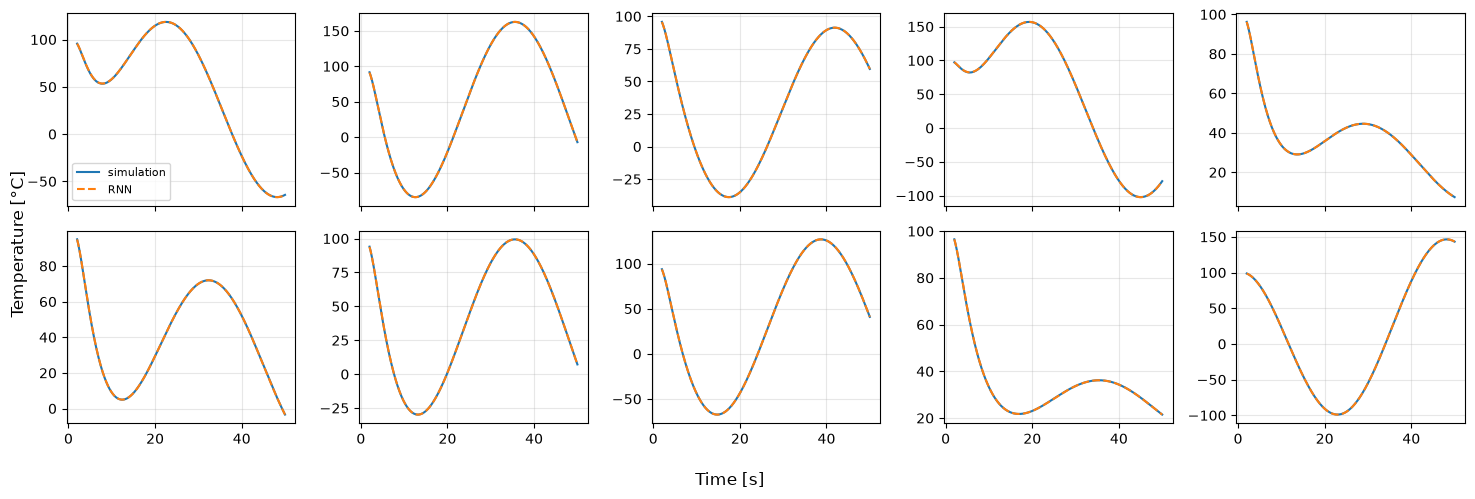

R² on the test simulations: 1.0000


In [9]:
def predict(series):
    """One-step-ahead predictions for a whole simulation, in °C."""
    windows, _ = make_windows(series)
    with torch.no_grad():
        y = model(torch.from_numpy(np.ascontiguousarray(windows))).numpy()
    return y * (y_max - y_min) + y_min


fig, axes = plt.subplots(2, 5, figsize=(15, 5), sharex=True)
true_values, predicted_values = [], []
for ax, series in zip(axes.flat, test_data):
    prediction = predict(series)
    true = series["y"].to_numpy()[seq_length:]
    true_values.append(true)
    predicted_values.append(prediction)
    ax.plot(series["time"][seq_length:], true, label="simulation")
    ax.plot(series["time"][seq_length:], prediction, "--", label="RNN")
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.supxlabel("Time [s]")
fig.supylabel("Temperature [°C]")
plt.tight_layout()
plt.show()

true_values = np.concatenate(true_values)
predicted_values = np.concatenate(predicted_values)
r2 = 1 - np.sum((true_values - predicted_values) ** 2) / np.sum((true_values - true_values.mean()) ** 2)
print(f"R² on the test simulations: {r2:.4f}")

The network follows the simulator closely. That is good enough for a
demonstration, so we move on to the export.

## Bake the normalisation into the model

So far the scaling of inputs and outputs lives in Python, outside the
network. An FMU built from `HeatRNN` alone would expect normalised inputs and
return normalised outputs, which is not what the user of the FMU wants to
deal with.

The fix is to wrap the network in a module that scales the inputs, calls the
network and scales the output back. The four constants are stored with
[`register_buffer`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_buffer):
they are saved with the model and exported to ONNX, but they are not trained.

In [10]:
class NormalizedModel(nn.Module):

    def __init__(self, model, x_min, x_max, y_min, y_max):
        super().__init__()
        self.model = model
        self.register_buffer("x_min", torch.tensor(x_min, dtype=torch.float32))
        self.register_buffer("x_max", torch.tensor(x_max, dtype=torch.float32))
        self.register_buffer("y_min", torch.tensor(y_min, dtype=torch.float32))
        self.register_buffer("y_max", torch.tensor(y_max, dtype=torch.float32))

    def forward(self, x):
        x = (x - self.x_min) / (self.x_max - self.x_min)
        y = self.model(x)
        return y * (self.y_max - self.y_min) + self.y_min


normalized_model = NormalizedModel(model, x_min, x_max, y_min, y_max)
normalized_model.eval()

NormalizedModel(
  (model): HeatRNN(
    (rnn): RNN(2, 32, batch_first=True)
    (fc1): Linear(in_features=32, out_features=1, bias=True)
  )
)

## Export to ONNX

The example input fixes the shape of the `input` node: one window of 200
steps with 2 features, that is `(1, 200, 2)`.

In [11]:
model_name = "example3"
onnx_model_path = f"{model_name}.onnx"

torch.onnx.export(
    normalized_model,
    (torch.randn(1, seq_length, input_size),),
    onnx_model_path,
    input_names=["input"],
    output_names=["output"],
    external_data=False,  # keep the whole model in a single file
    verbose=False,
)

onnx.checker.check_model(onnx.load(onnx_model_path))

## The model description

The model description is as short as in the previous examples: one input
node and one output node.

In [12]:
model_description = {
    "name": "example3",
    "description": "A simple RNN example.",
    "FMIVersion": "2.0",
    "inputs": [
        {"name": "input", "description": "A scalar input to the model."}
    ],
    "outputs": [
        {"name": "output", "description": "The output array."}
    ]
}

with open(f"{model_name}Description.json", "w", encoding="utf-8") as f:
    json.dump(model_description, f, indent=4)

## Build the FMU

In [13]:
from loguru import logger
from onnx2fmu.app import build

logger.disable("onnx2fmu")  # keep the notebook output short

build(
    model_path=onnx_model_path,
    model_description_path=f"{model_name}Description.json",
    target_folder="temp",
)

The `input` node has 1 × 200 × 2 = 400 elements, so the FMU has 400 scalar
inputs. They are named `input_0_<step>_<feature>`: `input_0_0_0` is the edge
temperature at the oldest step of the window, and `input_0_199_1` is the
centre temperature at the most recent one.

In [14]:
from fmpy import read_model_description

variables = read_model_description(f"{model_name}.fmu").modelVariables
inputs = [v.name for v in variables if v.causality == "input"]
outputs = [v.name for v in variables if v.causality == "output"]

print(f"{len(inputs)} inputs: {inputs[0]}, {inputs[1]}, ..., {inputs[-1]}")
print(f"{len(outputs)} output: {outputs[0]}")

400 inputs: input_0_0_0, input_0_0_1, ..., input_0_199_1
1 output: output_0


## Prepare the input signals

At every step the FMU needs a complete window. We take one of the test
simulations and write its windows to a CSV file, one row per step and one
column per FMU input. The values are in degrees: the normalisation now
happens inside the FMU.

In a real application, the system that hosts the FMU is responsible for
keeping this window up to date. If you would rather have the FMU do it,
use feedback states as in [Example 4](../example4/example4.ipynb).

In [15]:
series = test_data[1]

raw = series[["u", "y"]].to_numpy()
windows = np.lib.stride_tricks.sliding_window_view(raw, seq_length, axis=0)
windows = windows.transpose(0, 2, 1)[:-1]          # (steps, 200, 2)
n_steps = len(windows)

df_input = pd.DataFrame(
    windows.reshape(n_steps, -1),                  # row-major, like the FMU names
    columns=[f"input_0_{i}_{j}" for i in range(seq_length) for j in range(input_size)],
)
df_input.index.name = "time"
df_input.to_csv("input.csv")

print(f"{n_steps} steps, {df_input.shape[1]} input columns")

4800 steps, 400 input columns


## Simulate the FMU

In [16]:
from fmpy import simulate_fmu

signals = np.genfromtxt("input.csv", delimiter=",", names=True)

results = simulate_fmu(
    f"{model_name}.fmu",
    start_time=0,
    stop_time=n_steps,
    input=signals,
    output=["output_0"],
    output_interval=1,
    validate=True,
)

The row of the results at time `k + 1` holds the output for the window given
at time `k`, so we drop the first row. We compare the FMU with the PyTorch
model and with the simulator.

largest difference between FMU and PyTorch: 1.22e-04 °C


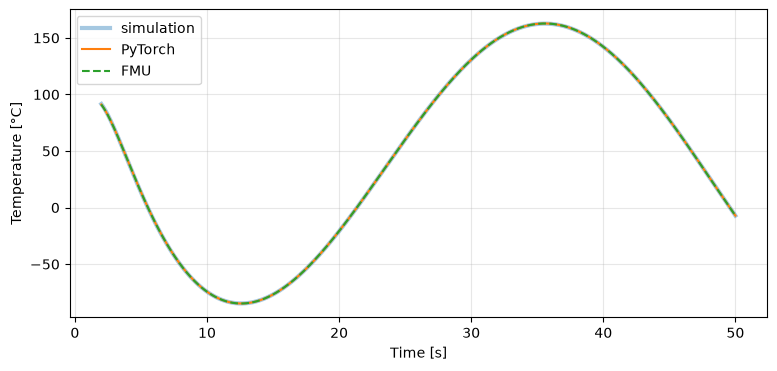

In [17]:
fmu_prediction = results["output_0"][1:n_steps + 1]
torch_prediction = predict(series)
true = series["y"].to_numpy()[seq_length:]
time = series["time"].to_numpy()[seq_length:]

print(f"largest difference between FMU and PyTorch: "
      f"{np.abs(fmu_prediction - torch_prediction).max():.2e} °C")

plt.figure(figsize=(9, 4))
plt.plot(time, true, lw=3, alpha=0.4, label="simulation")
plt.plot(time, torch_prediction, label="PyTorch")
plt.plot(time, fmu_prediction, "--", label="FMU")
plt.xlabel("Time [s]")
plt.ylabel("Temperature [°C]")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The FMU and the PyTorch model give the same predictions, up to the precision
of 32-bit arithmetic, and both follow the simulator.

## What next

- [Example 4](../example4/example4.ipynb) lets the FMU keep the history
  itself, with feedback states.
- [Example 5](../example5/example5.ipynb) exports a network that computes a
  time derivative, as a Model Exchange FMU.